# PRML Assignment 7 — GMM classification

## 1. Synthetic dataset 


Synthetic dataset: [(4000, 2), (4000, 2)]


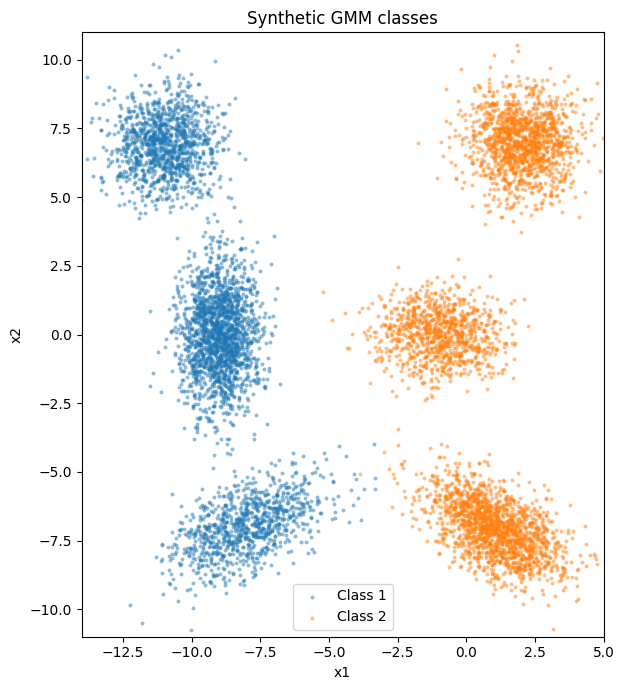

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
from PIL import Image

random.seed(42)
rng = np.random.default_rng(42)

# Separate seed for the linear congruential generator (LCG).
_uniform_state = 42

def uniform(a, b, n):
    global _uniform_state
    multiplier, increment, modulus = 1664525, 1013904223, 2**32
    u = np.empty(n, dtype=float)
    for i in range(n):
        _uniform_state = (multiplier * _uniform_state + increment) % modulus
        u[i] = _uniform_state / modulus
    return a + (b - a) * u

def standard_normal():
    while True:
        u1, u2 = uniform(-1, 1, 2)
        s = u1*u1 + u2*u2
        if 0 < s < 1:
            f = np.sqrt(-2 * np.log(s) / s)
            return u1*f, u2*f

def generate_gaussian(mean, covariance):
    z1, z2 = standard_normal()
    C = np.asarray(covariance, dtype=float)
    eigenvalues, eigenvectors = np.linalg.eigh(C)
    if np.any(eigenvalues <= 0):
        raise ValueError("Covariance must be positive definite.")
    z = np.array([z1, z2])
    point = np.asarray(mean) + eigenvectors @ (
        np.sqrt(eigenvalues) * z
    )
    return point.tolist()

def generate_data(N, weights, means, covariances):
    points = []
    labels = []
    for _ in range(N):
        u = uniform(0, 1, 1)[0]
        if u < weights[0]: k = 0
        elif u < weights[0] + weights[1]: k = 1
        else: k = 2
        points.append(generate_gaussian(means[k], covariances[k]))
        labels.append(k)
    return np.array(points), np.array(labels)

N, K = 4000, 3
weights1 = [0.30, 0.45, 0.25]
means1 = [[-11, 7], [-9, 0], [-8, -7]]
weights2 = [0.35, 0.25, 0.40]
means2 = [[2, 7], [-1, 0], [1, -7]]
covariances1 = [ [[1,0],[0,1]], [[.5,0],[0,2]], [[2,.8],[.8,1]] ]
covariances2 = [ [[1,0],[0,1]], [[1.5,0],[0,.7]], [[1.5,-.6],[-.6,1]] ]
colors = [["tab:blue", "tab:cyan", "navy"], ["tab:orange", "tab:red", "goldenrod"]]
XLIM, YLIM = (-14, 5), (-11, 11)
class_samples = []
for w,m,c in [(weights1,means1,covariances1),(weights2,means2,covariances2)]:
    X, _ = generate_data(N, w, m, c)
    class_samples.append(X)
print('Synthetic dataset:', [x.shape for x in class_samples])
# Plot 
class_labels = []
plt.figure(figsize=(9, 7))
for c, X in enumerate(class_samples):
    plt.scatter(X[:, 0], X[:, 1], s=8, alpha=.5, linewidths=0,
                color=colors[c][0], label=f"Class {c+1}")
plt.xlim(XLIM); plt.ylim(YLIM); plt.gca().set_aspect('equal')
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('Synthetic GMM classes')
plt.legend(); plt.tight_layout(); plt.show()


## 2. Train/test split (no K-Means)

In [2]:
def shuffle(X):
    X = X.copy()
    for i in range(len(X) - 1, 0, -1):
        j = int(random.random() * (i + 1))
        X[[i, j]] = X[[j, i]]
    return X

train, test = [], []
for X in class_samples:
    X = shuffle(X)
    train.append(X[:int(.8 * len(X))])
    test.append(X[int(.8 * len(X)):])
print('Train:', [x.shape for x in train], 'Test:', [x.shape for x in test])

Train: [(3200, 2), (3200, 2)] Test: [(800, 2), (800, 2)]


## 3. Object-oriented GMM with random initialization and EM

In [3]:
def logsumexp(A, axis=1):
    m = np.max(A, axis=axis, keepdims=True)
    return (m + np.log(np.exp(A-m).sum(axis=axis, keepdims=True))).squeeze(axis)

class GMM:
    def __init__(self, K=3, covariance_type='full', max_iter=40, reg=1e-4, seed=42):
        self.K = K
        self.covariance_type = covariance_type
        self.max_iter = max_iter
        self.reg = reg
        self.seed = seed
        self.rng = np.random.default_rng(seed)

    def component_log_prob(self, X):
        N, D = X.shape
        values = np.zeros((N, self.K))
        for k in range(self.K):
            diff = X - self.means[k]
            if self.covariance_type == 'diag':
                var = self.covs[k]
                log_det = np.log(var).sum()
                mahal = ((diff*diff)/var).sum(axis=1)
            else:
                C = self.covs[k]
                sign, log_det = np.linalg.slogdet(C)
                if sign <= 0: raise ValueError('Covariance is not positive definite')
                mahal = (diff * np.linalg.solve(C, diff.T).T).sum(axis=1)
            values[:, k] = np.log(self.weights[k] + 1e-15) - 0.5*(D*np.log(2*np.pi)+log_det+mahal)
        return values

    def score_samples(self, X):
        return logsumexp(self.component_log_prob(X), axis=1)

    def fit(self, X, X_dev=None):
        X = np.asarray(X, dtype=float)
        if X_dev is not None:
            X_dev = np.asarray(X_dev, dtype=float)
            if X_dev.ndim != 2 or X_dev.shape[1] != X.shape[1]:
                raise ValueError("Development data must have the same number of features as training data")
        N, D = X.shape
        if N < self.K:
            raise ValueError('Need at least K training samples')
        # Random distinct training points; no K-Means step.
        indices = self.rng.choice(N, size=self.K, replace=False)
        self.means = X[indices].copy()
        self.weights = np.full(self.K, 1.0 / self.K)
        if self.covariance_type == 'diag':
            base_cov = X.var(axis=0) + self.reg
        elif self.covariance_type == 'full':
            base_cov = np.atleast_2d(np.cov(X, rowvar=False)) + self.reg * np.eye(D)
        else:
            raise ValueError("covariance_type must be 'diag' or 'full'")
        self.covs = np.array([base_cov.copy() for _ in range(self.K)])
        self.history = []
        self.dev_history = []
        for iteration in range(self.max_iter):
            log_joint = self.component_log_prob(X)
            log_total = logsumexp(log_joint, axis=1)
            resp = np.exp(log_joint - log_total[:, None])
            Nk = resp.sum(axis=0) + 1e-10
            self.weights = Nk / Nk.sum()
            self.means   = resp.T @ X / Nk[:, None]
            covs = []
            for k in range(self.K):
                diff = X - self.means[k]
                if self.covariance_type == 'diag':
                    var = (resp[:,k,None] * diff**2).sum(axis=0)/Nk[k]
                    covs.append(var + self.reg)
                else:
                    C = (diff * resp[:,k,None]).T @ diff / Nk[k]
                    covs.append(C + self.reg*np.eye(D))
            self.covs = np.array(covs)
            # Evaluate both datasets using the UPDATED parameters.
            # Only X influences the E/M parameter updates; X_dev is evaluation-only.
            self.history.append(self.score_samples(X).mean())
            if X_dev is not None:
                self.dev_history.append(self.score_samples(X_dev).mean())
            if iteration > 0 and abs(self.history[-1]-self.history[-2]) < 1e-5:
                break
        return self

def predict_class(models, X, class_priors=None):
    scores = np.column_stack([model.score_samples(X) for model in models])
    if class_priors is not None:
        scores += np.log(class_priors)
    return scores.argmax(axis=1), scores

def confusion(y_true, y_pred, classes):
    cm = np.zeros((len(classes), len(classes)), dtype=int)
    for a,b in zip(y_true, y_pred):
        cm[classes.index(int(a)), classes.index(int(b))] += 1
    return cm

def print_results(cm, classes):
    print('Rows = true label; columns = predicted label')
    print('Labels:', classes)
    print(cm)
    print('Accuracy:', round(np.trace(cm)/cm.sum(), 4))
    print('Per-class recall:', dict(zip(classes, np.round(cm.diagonal()/cm.sum(axis=1), 4))))
class GMMClassifier:
    """One class-conditional GMM per class; maximum log-density prediction."""
    def __init__(self, K=3, covariance_type='full', max_iter=60, reg=1e-4, seed=42):
        self.K = K
        self.covariance_type = covariance_type
        self.max_iter = max_iter
        self.reg = reg
        self.seed = seed

    def fit(self, X, y, X_dev=None, y_dev=None):
        X, y = np.asarray(X), np.asarray(y)
        self.classes_ = np.unique(y)
        self.models_ = []
        for i, label in enumerate(self.classes_):
            dev = None
            if X_dev is not None:
                if y_dev is None:
                    raise ValueError('y_dev is required when X_dev is provided')
                dev = np.asarray(X_dev)[np.asarray(y_dev) == label]
            model = GMM(self.K, self.covariance_type, self.max_iter,
                        self.reg, seed=self.seed + i)
            self.models_.append(model.fit(X[y == label], X_dev=dev))
        return self

    def predict_log_scores(self, X):
        return np.column_stack([m.score_samples(X) for m in self.models_])

    def predict(self, X):
        scores = self.predict_log_scores(X)
        return self.classes_[np.argmax(scores, axis=1)]


## 4. Part 1: fit class-wise 2D GMMs, classify test points, draw boundary


In [4]:
classifier_2d = GMMClassifier(K=3, covariance_type='full', max_iter=60, reg=1e-5, seed=42)
X_train_2d = np.vstack(train)
y_train_2d = np.concatenate([np.full(len(X), i) for i, X in enumerate(train)])
classifier_2d.fit(X_train_2d, y_train_2d)
models_2d = classifier_2d.models_
X_test_2d = np.vstack(test)
y_test_2d = np.concatenate([np.full(len(X), i) for i, X in enumerate(test)])
pred_2d = classifier_2d.predict(X_test_2d)
cm_2d = confusion(y_test_2d, pred_2d, [0, 1])
print_results(cm_2d, [0, 1])
for c, model in enumerate(models_2d):
    print(f'Class {c+1} weights:', np.round(model.weights, 3))
    print('Means:\n', np.round(model.means, 3))
    print('Covariances:\n', np.round(model.covs, 3))

Rows = true label; columns = predicted label
Labels: [0, 1]
[[800   0]
 [  1 799]]
Accuracy: 0.9994
Per-class recall: {0: 1.0, 1: 0.9988}
Class 1 weights: [0.301 0.464 0.235]
Means:
 [[-11.01    6.941]
 [ -8.998  -0.031]
 [ -7.929  -6.928]]
Covariances:
 [[[0.962 0.026]
  [0.026 1.004]]

 [[0.506 0.013]
  [0.013 1.982]]

 [[2.004 0.774]
  [0.774 0.98 ]]]
Class 2 weights: [0.412 0.243 0.345]
Means:
 [[ 1.003e+00 -7.050e+00]
 [-9.720e-01  1.000e-03]
 [ 2.019e+00  7.002e+00]]
Covariances:
 [[[ 1.578 -0.68 ]
  [-0.68   0.987]]

 [[ 1.36  -0.03 ]
  [-0.03   0.702]]

 [[ 0.999 -0.021]
  [-0.021  1.054]]]


### GMM-only decision boundary and EM convergence

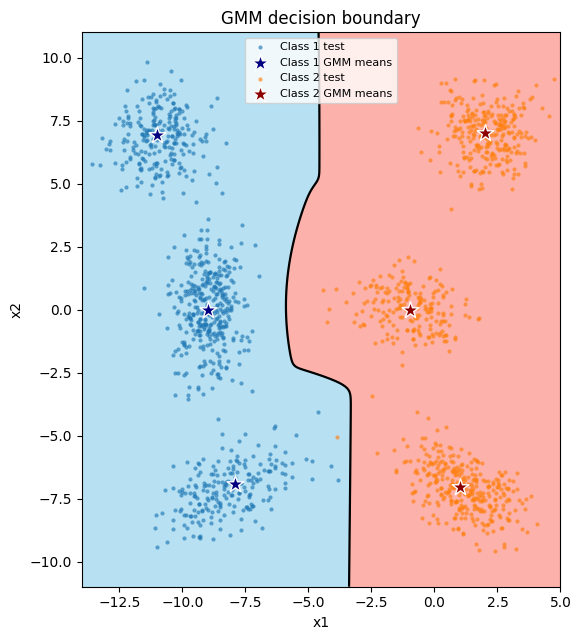

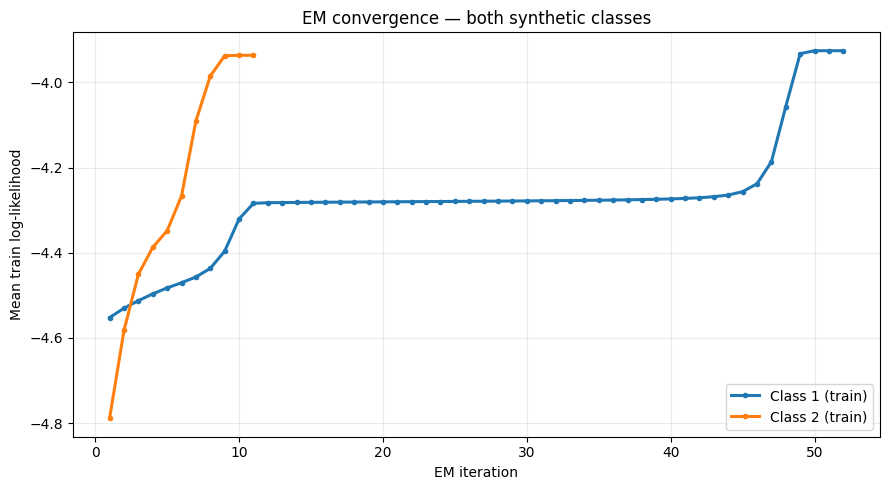

In [5]:
gx, gy = np.meshgrid(np.linspace(*XLIM, 300), np.linspace(*YLIM, 300))
grid = np.column_stack((gx.ravel(), gy.ravel()))
log_scores = classifier_2d.predict_log_scores(grid)
boundary = (log_scores[:, 0] - log_scores[:, 1]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.contourf(gx, gy, -boundary, levels=[-np.inf, 0, np.inf],
            colors=['skyblue', 'salmon'], alpha=0.6)
ax.contour(gx, gy, boundary, levels=[0], colors='k', linewidths=1.6)
for c, X in enumerate(test):
    ax.scatter(X[:, 0], X[:, 1], s=9, alpha=.65, linewidths=0,
               color=colors[c][0], label=f'Class {c+1} test')
    ax.scatter(models_2d[c].means[:, 0], models_2d[c].means[:, 1],
               marker='*', s=160, color=['navy', 'darkred'][c],
               edgecolor='white', zorder=5, label=f'Class {c+1} GMM means')
ax.set(xlim=XLIM, ylim=YLIM, xlabel='x1', ylabel='x2',
       title='GMM decision boundary')
ax.set_aspect('equal')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for c, model in enumerate(models_2d):
    ax.plot(range(1, len(model.history) + 1), model.history,
            color=colors[c][0], linewidth=2.2, marker='o', markersize=3,
            label=f'Class {c+1} (train)')
ax.set(title='EM convergence — both synthetic classes',
       xlabel='EM iteration', ylabel='Mean train log-likelihood')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. MNIST: load 28×28 originals and compress to 14x14





In [6]:
ZIP_PATH = Path('TEAM_3.zip')
if not ZIP_PATH.exists():
    ZIP_PATH = Path('/mnt/data/TEAM_3.zip')
DIGITS = [1, 8, 9]
IMAGE_SIZE = 14

# A consistent resize for training, dev and test. Returns 289 features.
def image_features(image):
    gray = image.convert('L')
    small = gray.resize((IMAGE_SIZE, IMAGE_SIZE), resample=Image.Resampling.BOX)
    return np.asarray(small, dtype=np.float64).ravel() / 255.0

def read_split(z, split):
    X, y, originals = [], [], []
    for digit in DIGITS:
        prefix = f'TEAM_3/{split}/{digit}/'
        names = sorted(name for name in z.namelist()
                       if name.startswith(prefix) and name.endswith('.png'))
        print(split, digit, len(names))
        for name in names:
            with Image.open(BytesIO(z.read(name))) as im:
                gray = im.convert('L')
                originals.append(np.asarray(gray, dtype=np.uint8).copy())
                X.append(image_features(gray))
            y.append(digit)
    return np.asarray(X, dtype=np.float64), np.asarray(y, dtype=int), np.asarray(originals, dtype=np.uint8)

with ZipFile(ZIP_PATH) as z:
    X_train, y_train, original_train = read_split(z, 'train')
    X_dev, y_dev, original_dev = read_split(z, 'dev')
    X_test, y_test, original_test = read_split(z, 'test')
print('Feature shapes:', X_train.shape, X_dev.shape, X_test.shape)
print('Original image shapes:', original_train.shape, original_dev.shape, original_test.shape)


train 1 5383
train 8 4674
train 9 4776
dev 1 1359
dev 8 1177
dev 9 1173
test 1 1135
test 8 974
test 9 1009
Feature shapes: (14833, 196) (3709, 196) (3118, 196)
Original image shapes: (14833, 28, 28) (3709, 28, 28) (3118, 28, 28)


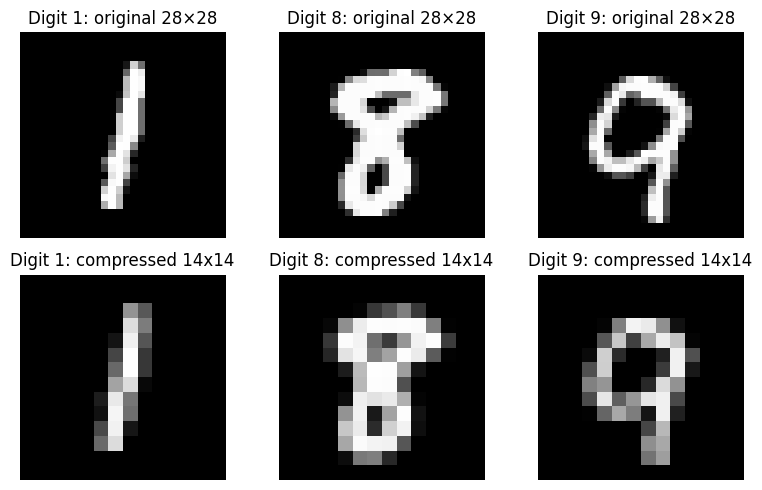

In [7]:
# Show the actual original and the 17x17 representation used by the GMM.
fig, axes = plt.subplots(2, len(DIGITS), figsize=(8, 5))
for col, digit in enumerate(DIGITS):
    idx = np.flatnonzero(y_train == digit)[0]
    axes[0, col].imshow(original_train[idx], cmap='gray', vmin=0, vmax=255,
                        interpolation='nearest')
    axes[0, col].set_title(f'Digit {digit}: original 28×28')
    axes[1, col].imshow(X_train[idx].reshape(IMAGE_SIZE, IMAGE_SIZE), cmap='gray',
                        vmin=0, vmax=1, interpolation='nearest')
    axes[1, col].set_title(f'Digit {digit}: compressed 14x14')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout(); plt.show()


## 6. Train a diagonal-covariance GMM for each digit


In [8]:
K = 3
mnist_classifier = GMMClassifier(K=K, covariance_type='diag', max_iter=35,
                                 reg=1e-3, seed=42)
mnist_classifier.fit(X_train, y_train, X_dev=X_dev, y_dev=y_dev)
models_mnist = mnist_classifier.models_
for digit, model in zip(mnist_classifier.classes_, models_mnist):
    print(f'Digit {digit}: {len(model.history)} EM iterations; '
          f'final train mean logL = {model.history[-1]:.2f}; '
          f'dev mean logL = {model.dev_history[-1]:.2f}')

Digit 1: 17 EM iterations; final train mean logL = 376.50; dev mean logL = 374.79
Digit 8: 35 EM iterations; final train mean logL = 262.76; dev mean logL = 263.00
Digit 9: 35 EM iterations; final train mean logL = 292.98; dev mean logL = 290.88


### MNIST development-set evaluation and EM convergence



MNIST DEVELOPMENT RESULTS (K = 3 )
Rows = true label; columns = predicted label
Labels: [1, 8, 9]
[[1315   36    8]
 [  26 1122   29]
 [   4   77 1092]]
Accuracy: 0.9515
Per-class recall: {1: 0.9676, 8: 0.9533, 9: 0.9309}


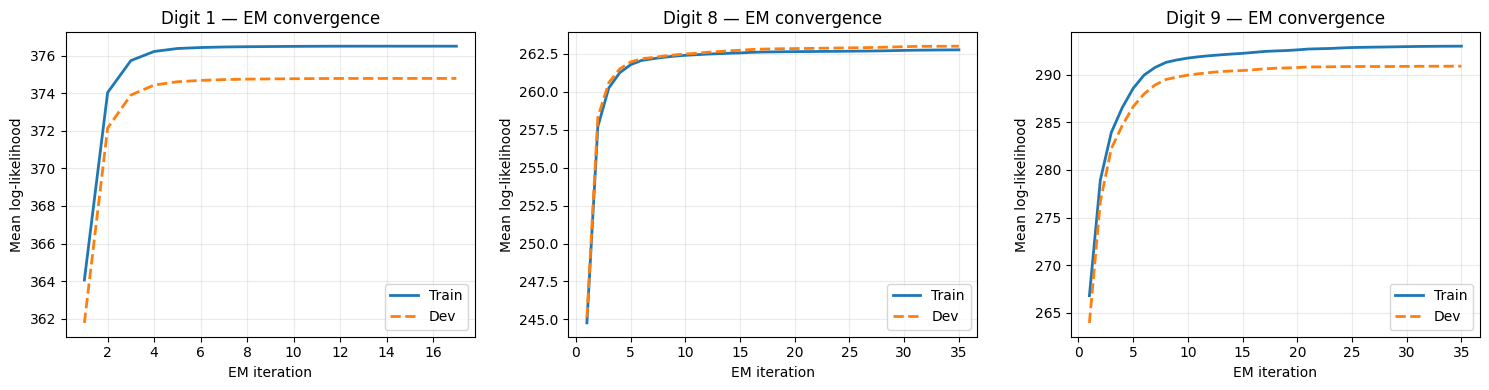

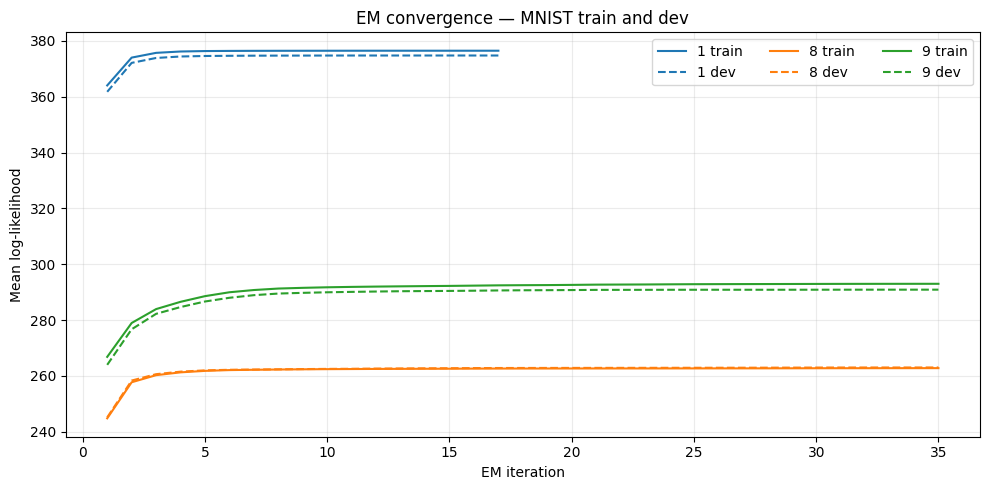

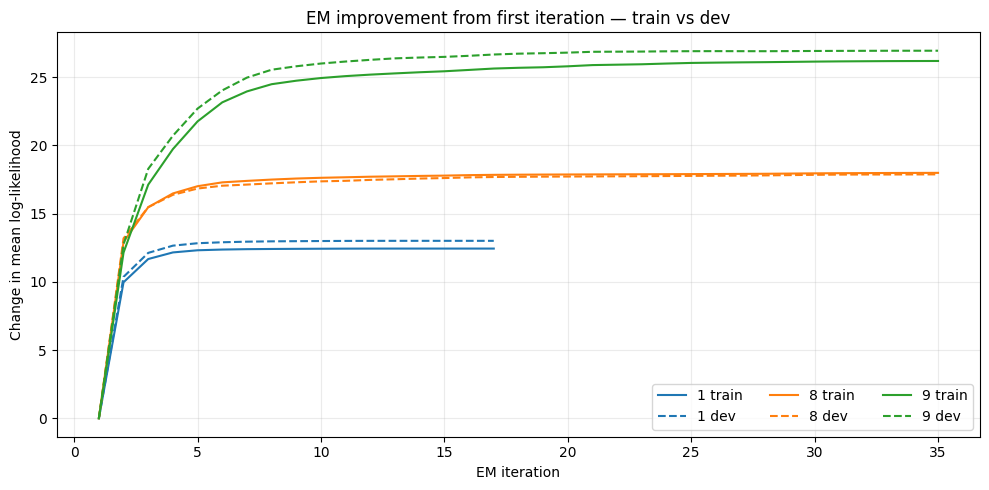

In [9]:
# Separate development classification evaluation (no test data used).
dev_scores = mnist_classifier.predict_log_scores(X_dev)
dev_pred = mnist_classifier.predict(X_dev)
cm_dev = confusion(y_dev, dev_pred, DIGITS)
print('MNIST DEVELOPMENT RESULTS (K =', K, ')')
print_results(cm_dev, DIGITS)

fig, axes = plt.subplots(1, len(DIGITS), figsize=(15, 4))
for i, digit in enumerate(DIGITS):
    model = models_mnist[i]
    iters = np.arange(1, len(model.history) + 1)
    axes[i].plot(iters, model.history, color='tab:blue', linewidth=2, label='Train')
    axes[i].plot(iters, model.dev_history, color='tab:orange', linestyle='--', linewidth=2, label='Dev')
    axes[i].set(title=f'Digit {digit} — EM convergence', xlabel='EM iteration', ylabel='Mean log-likelihood')
    axes[i].grid(alpha=.25)
    axes[i].legend()
plt.tight_layout()
plt.show()

# One plot with all three digits; solid=train, dashed=dev.
fig, ax = plt.subplots(figsize=(10, 5))
mnist_colors = ['tab:blue', 'tab:orange', 'tab:green']
for i, digit in enumerate(DIGITS):
    model = models_mnist[i]
    iters = np.arange(1, len(model.history) + 1)
    ax.plot(iters, model.history, color=mnist_colors[i], label=f'{digit} train')
    ax.plot(iters, model.dev_history, color=mnist_colors[i], linestyle='--', label=f'{digit} dev')
ax.set(title='EM convergence — MNIST train and dev', xlabel='EM iteration', ylabel='Mean log-likelihood')
ax.legend(ncol=3)
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

# Normalize each curve to its first iteration to compare IMPROVEMENT.
fig, ax = plt.subplots(figsize=(10, 5))
for i, digit in enumerate(DIGITS):
    model = models_mnist[i]
    iters = np.arange(1, len(model.history) + 1)
    ax.plot(iters, np.array(model.history) - model.history[0],
            color=mnist_colors[i], label=f'{digit} train')
    ax.plot(iters, np.array(model.dev_history) - model.dev_history[0],
            color=mnist_colors[i], linestyle='--', label=f'{digit} dev')
ax.set(title='EM improvement from first iteration — train vs dev',
       xlabel='EM iteration', ylabel='Change in mean log-likelihood')
ax.legend(ncol=3)
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 7. Final test classification and confusion matrix


MNIST TEST results; K= 3
Rows = true label; columns = predicted label
Labels: [1, 8, 9]
[[1110   25    0]
 [  22  929   23]
 [   8   51  950]]
Accuracy: 0.9586
Per-class recall: {1: 0.978, 8: 0.9538, 9: 0.9415}


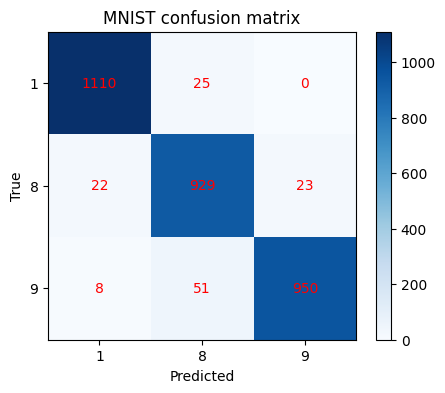

In [10]:
test_scores = mnist_classifier.predict_log_scores(X_test)
test_pred = mnist_classifier.predict(X_test)
cm_mnist = confusion(y_test, test_pred, DIGITS)
print('MNIST TEST results; K=', K)
print_results(cm_mnist, DIGITS)
plt.figure(figsize=(5,4))
plt.imshow(cm_mnist, cmap='Blues')
plt.xticks(range(3),DIGITS); plt.yticks(range(3),DIGITS)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('MNIST confusion matrix')
for i in range(3):
    for j in range(3):
        plt.text(j,i,str(cm_mnist[i,j]),ha='center',va='center',color='red')
plt.colorbar(); plt.show()

## 8. Inspect mistakes using the original 28×28 images




Misclassified examples: 129


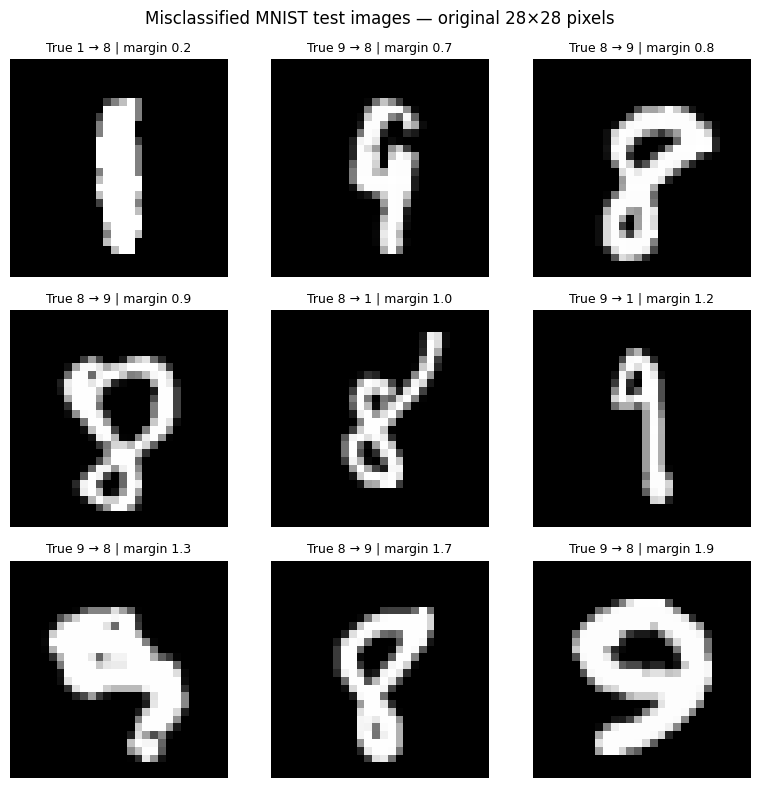

1 mistaken for 8: 25
1 mistaken for 9: 0
8 mistaken for 1: 22
8 mistaken for 9: 23
9 mistaken for 1: 8
9 mistaken for 8: 51


In [11]:
order = np.sort(test_scores, axis=1)
margin = order[:, -1] - order[:, -2]
wrong = np.where(test_pred != y_test)[0]
print('Misclassified examples:', len(wrong))
if len(wrong):
    chosen = wrong[np.argsort(margin[wrong])[:9]]
    fig, axes = plt.subplots(3, 3, figsize=(8, 8))
    for ax, idx in zip(axes.flat, chosen):
        ax.imshow(original_test[idx], cmap='gray', vmin=0, vmax=255,
                  interpolation='nearest')
        ax.set_title(f'True {y_test[idx]} → {test_pred[idx]} | margin {margin[idx]:.1f}', fontsize=9)
        ax.axis('off')
    for ax in axes.flat[len(chosen):]:
        ax.axis('off')
    plt.suptitle('Misclassified MNIST test images — original 28×28 pixels')
    plt.tight_layout(); plt.show()
for true_digit in DIGITS:
    for pred_digit in DIGITS:
        if true_digit != pred_digit:
            print(f'{true_digit} mistaken for {pred_digit}:',
                  np.sum((y_test == true_digit) & (test_pred == pred_digit)))


## 9. Interpret GMM parameters



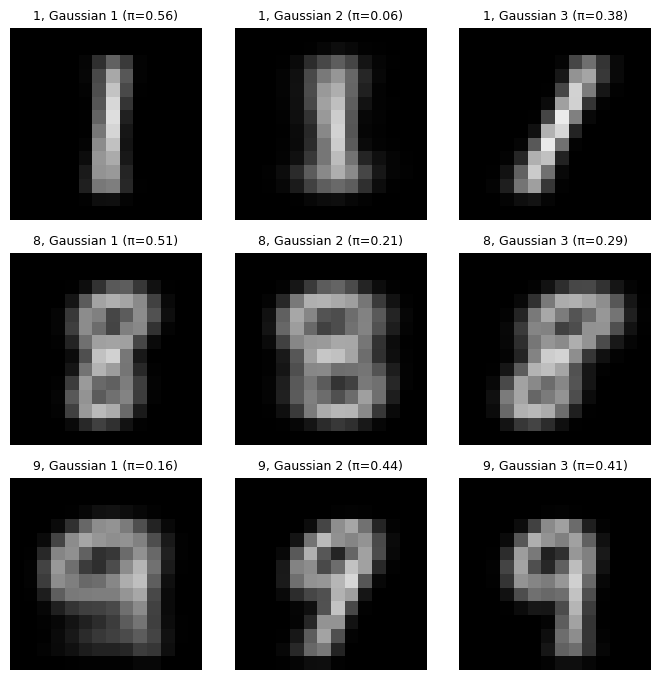

In [12]:
fig, axes = plt.subplots(len(DIGITS), K, figsize=(2.3*K, 2.3*len(DIGITS)))
axes = np.asarray(axes).reshape(len(DIGITS), K)
for i, digit in enumerate(DIGITS):
    model = models_mnist[i]
    for k in range(K):
        axes[i,k].imshow(model.means[k].reshape(IMAGE_SIZE, IMAGE_SIZE), cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        axes[i,k].set_title(f'{digit}, Gaussian {k+1} (π={model.weights[k]:.2f})',fontsize=9)
        axes[i,k].axis('off')
plt.tight_layout(); plt.show()